# 04 - Walk-forward yield model and ZCZ backtest: results

This notebook re-draws the key tables and figures of `reports/phase6_results.md` from the saved outputs (`reports/*.csv`, `data/processed/backtest_trades.parquet`, `data/processed/model_predictions.parquet`). It does not refit anything: reproduce the numbers with `uv run python scripts/run_backtest.py`.

**Stage A** predicts the final US yield surprise (final yield minus an OLS trend fitted on 1990..Y-1) from three feature groups at 7 snapshots between Jun 15 and Sep 15: W weather, C crop condition, S satellite. Ridge, standardised features, alpha chosen by leave-one-out inside the training seasons, expanding walk-forward (12 scored seasons, 2014-2025). **Stage B** trades 1 ZCZ contract weekly Jun-Sep, 2014-2026, after costs, with three signal rules: `level`, `change` and `vs_usda`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cornsat.config import DATA_PROCESSED, ROOT

REPORTS = ROOT / "reports"
SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
C1, C2, C3, NEUTRAL = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2,
    "ytick.color": INK2, "text.color": INK, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False, "lines.linewidth": 1.6,
})
pd.set_option("display.width", 160)

accA = pd.read_csv(REPORTS / "stageA_accuracy.csv")
paired = pd.read_csv(REPORTS / "stageA_paired.csv")
summ = pd.read_csv(REPORTS / "stageB_summary.csv").set_index("strategy")
seas = pd.read_csv(REPORTS / "stageB_season_pnl.csv").set_index("season")
sat = pd.read_csv(REPORTS / "stageB_satellite.csv")
trades = pd.read_parquet(DATA_PROCESSED / "backtest_trades.parquet")
preds = pd.read_parquet(DATA_PROCESSED / "model_predictions.parquet")
print("trades", trades.shape, "| predictions", preds.shape, "| strategies", trades["strategy"].nunique())

trades (4050, 10) | predictions (3225, 17) | strategies 18

## Stage A: walk-forward RMSE (bu/ac), seasons 2014-2025

Rows are feature sets and baselines; `trend` is the trend-only forecast (predict a surprise of 0) and `USDA` is the USDA forecast minus trend (available from Aug 15). Lower is better. A cell is only interesting if it beats `trend` (6.4) in the same column.

snapshot  Jun15  Jul01  Jul15  Aug01  Aug15  Sep01  Sep15  avg
set                                                           
W          12.6   10.4    8.3    7.6    7.6    6.2    7.1  8.6
C           6.2   11.1    5.5    7.4    6.2    5.3    5.4  6.7
S           7.0   10.4    6.8    9.4    6.7    6.8    4.8  7.4
W+C         6.6    9.3    6.7    8.1    6.7    4.8    6.6  7.0
W+S        14.4   10.0    8.5    6.7    6.5    5.6    4.8  8.1
C+S         6.1   11.8    6.4   10.2    7.4    6.5    4.5  7.6
W+C+S       6.6   10.1    6.9    9.7    8.1    5.0    5.6  7.4
trend       6.4    6.4    6.4    6.4    6.4    6.4    6.4  6.4
mean        9.7    9.7    9.7    9.7    9.7    9.7    9.7  9.7
usda        NaN    NaN    NaN    NaN    4.2    4.2    3.6  NaN

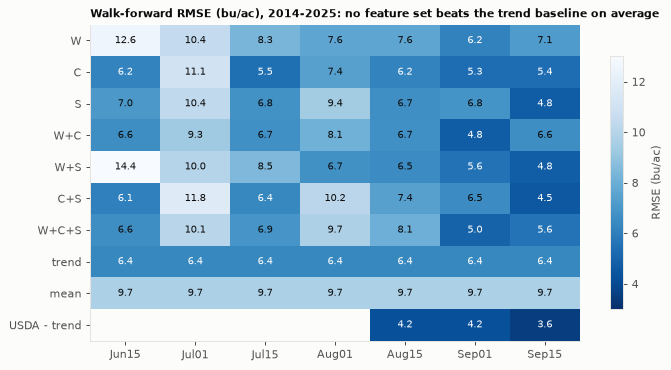

In [2]:
snaps = ["Jun15", "Jul01", "Jul15", "Aug01", "Aug15", "Sep01", "Sep15"]
order = ["W", "C", "S", "W+C", "W+S", "C+S", "W+C+S", "trend", "mean", "usda"]
wf = accA[accA["scheme"] == "wf"]
piv = wf.pivot_table(index="set", columns="snapshot", values="rmse").loc[order, snaps]
piv["avg"] = piv.drop(index=["usda"]).mean(axis=1)  # season-snapshot average (USDA has only 3 snapshots)
fig, ax = plt.subplots(figsize=(8, 4.2))
im = ax.imshow(piv[snaps].values, cmap="Blues_r", aspect="auto", vmin=3, vmax=13)
ax.set_xticks(range(len(snaps))); ax.set_xticklabels(snaps)
ax.set_yticks(range(len(order))); ax.set_yticklabels([o if o != "usda" else "USDA - trend" for o in order])
for i in range(len(order)):
    for j in range(len(snaps)):
        v = piv[snaps].values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8, color="white" if v < 6.5 else INK)
ax.grid(False)
ax.set_title("Walk-forward RMSE (bu/ac), 2014-2025: no feature set beats the trend baseline on average", loc="left", fontsize=9)
fig.colorbar(im, ax=ax, label="RMSE (bu/ac)", shrink=0.8)
fig.tight_layout()
piv.round(1)

Per set, the average over the 7 snapshots is in the `avg` column (the USDA row averages only its 3 snapshots, so it is not comparable). Trend-only is 6.4 and the best set (C) is 6.7. The USDA forecast beats every model from mid-August (4.2 and 3.6). Jun 15 W (12.6) and W+S (14.4) are driven by one prediction, 2018, from a nine-season ridge fit on a feature that is close to 0 in most early Junes.

## Predicted vs actual yield surprise

Walk-forward predictions for the best set by mean RMSE (C), against the USDA forecast minus trend. The dashed line is a perfect forecast.

best set by mean walk-forward RMSE: C

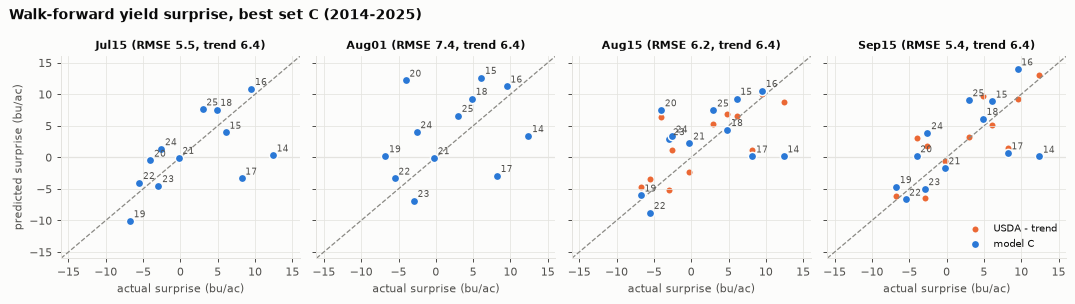

In [3]:
mean_rmse = piv.loc[["W", "C", "S", "W+C", "W+S", "C+S", "W+C+S"], "avg"]
best_set = mean_rmse.idxmin()
p = preds[(preds["kind"] == "snapshot") & (preds["scheme"] == "wf") & preds["actual"].notna()]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), sharex=True, sharey=True)
lim = (-16, 16)
for ax, sn in zip(axes, ["Jul15", "Aug01", "Aug15", "Sep15"]):
    m = p[(p["snapshot"] == sn) & (p["set"] == best_set)]
    u = p[(p["snapshot"] == sn) & (p["set"] == "usda")].dropna(subset=["pred"])
    ax.plot(lim, lim, color=NEUTRAL, lw=1, ls="--")
    ax.axhline(0, color=GRID, lw=1)
    if len(u):
        ax.scatter(u["actual"], u["pred"], s=36, color=C2, edgecolor=SURF, lw=1.2, label="USDA - trend")
    ax.scatter(m["actual"], m["pred"], s=44, color=C1, edgecolor=SURF, lw=1.2, zorder=3, label=f"model {best_set}")
    for _, r in m.iterrows():
        ax.annotate(str(r["season"])[2:], (r["actual"], r["pred"]), fontsize=7, color=INK2, xytext=(3, 3), textcoords="offset points")
    e = m["pred"] - m["actual"]
    ax.set_title(f"{sn} (RMSE {np.sqrt((e ** 2).mean()):.1f}, trend {np.sqrt((m['actual'] ** 2).mean()):.1f})", fontsize=9)
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel("actual surprise (bu/ac)")
axes[0].set_ylabel("predicted surprise (bu/ac)")
axes[-1].legend(loc="lower right", fontsize=8)
fig.suptitle(f"Walk-forward yield surprise, best set {best_set} (2014-2025)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
print("best set by mean walk-forward RMSE:", best_set)

## Stage B: strategies, ranked by net P&L

One ZCZ contract, weekly rebalance Jun-Sep 2014-2026, after costs. `pnl_lo`/`pnl_hi` is the season-block bootstrap 95% interval of net P&L; `p_random_full` is the random-sign p-value. No model strategy has a P&L interval that excludes zero on the positive side.

In [4]:
cols = ["net_pnl", "sharpe", "hit_rate", "max_dd", "trades", "costs", "pnl_lo", "pnl_hi", "seasons_pos", "p_random_full"]
summ[cols].sort_values("net_pnl", ascending=False).round(2)

               net_pnl  sharpe  hit_rate   max_dd  trades   costs    pnl_lo    pnl_hi  seasons_pos  p_random_full
strategy                                                                                                         
always_short   24035.0    0.93      0.56  10080.0      26   390.0   7885.00  40873.12           10           0.02
vs_usda|C       4190.0    0.35      0.54   3715.0      40   660.0  -6355.06  16047.62            7           0.27
change|W+C+S    1892.5    0.10      0.49   6520.0     123  2520.0  -7487.81  12117.56            6           0.33
level|W         1157.5    0.04      0.50   6687.5      59   930.0 -12945.31  15955.06            6           0.35
change|W        1105.0    0.00      0.53   9805.0     113  2070.0 -14667.56  14893.38            6           0.35
vs_usda|W        780.0    0.10      0.46   4225.0      38   570.0  -7380.19   9653.12            6           0.37
vs_usda|W+C      750.0   -0.02      0.44   4737.5      47   750.0  -8835.12  10645.56   

## Equity curves vs always-short

Cumulative net P&L of the weekly trades, concatenated across seasons (the saved trade table is weekly; the figure in the report is the same thing on a daily grid). The best model strategy (`vs_usda|C`, no satellite data) and the best strategy with S (`change|W+C+S`) are shown against always-short and always-long.

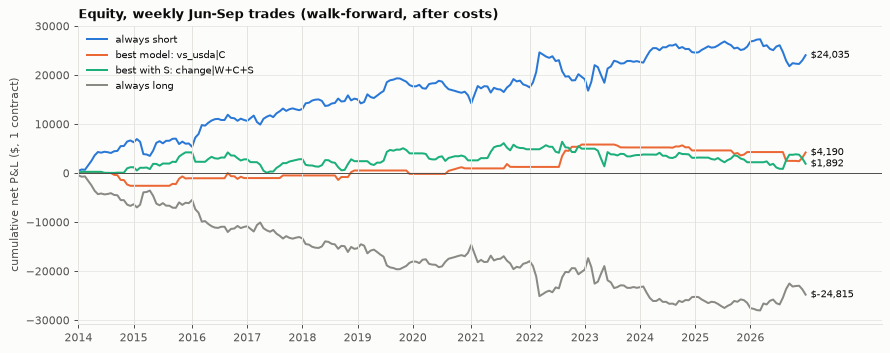

In [5]:
lines = [("always_short", "always short", C1), ("vs_usda|C", "best model: vs_usda|C", C2),
         ("change|W+C+S", "best with S: change|W+C+S", C3), ("always_long", "always long", NEUTRAL)]
fig, ax = plt.subplots(figsize=(10, 4))
for name, label, col in lines:
    t = trades[trades["strategy"] == name].sort_values("end")
    eq = t["net"].cumsum().to_numpy()
    assert abs(eq[-1] - summ.loc[name, "net_pnl"]) < 1e-6, name
    ax.plot(np.arange(len(eq)), eq, color=col, label=label)
    ax.annotate(f"${eq[-1]:,.0f}", (len(eq) - 1, eq[-1]), xytext=(4, 0), textcoords="offset points", fontsize=8, va="center")
t0 = trades[trades["strategy"] == "always_short"].sort_values("end")
starts = [0, *list(np.flatnonzero(np.diff(t0["season"].to_numpy())) + 1)]
for s in starts[1:]:
    ax.axvline(s, color=GRID, lw=0.8)
ax.set_xticks(starts); ax.set_xticklabels([str(t0["season"].iloc[i]) for i in starts])
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xlim(0, len(t0) * 1.1)
ax.set_ylabel("cumulative net P&L ($, 1 contract)")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("Equity, weekly Jun-Sep trades (walk-forward, after costs)", loc="left")
fig.tight_layout()

## Per-season P&L

season        2014  2015  2016  2017  2018  2019  2020  2021  2022  2023  2024  2025  2026
always_short  6645  -618  4795  1995  2358  2770 -2080  1982  1795  3182  1832  1120 -1742
vs_usda|C    -2605  1535    40   532  1010  -692  1120   302  4565  -592  -610  -330   -85
change|W+C+S  1180  3022 -1418    28  -400  1595 -1428  2265   122 -1300  -560  -910  -305
always_long  -6705   558 -4855 -2055 -2418 -2830  2020 -2042 -1855 -3242 -1892 -1180  1682

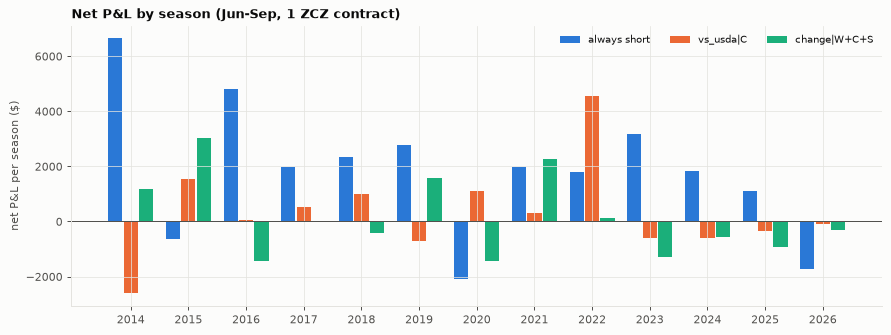

In [6]:
cols = [("always_short", "always short", C1), ("vs_usda|C", "vs_usda|C", C2), ("change|W+C+S", "change|W+C+S", C3)]
x = np.arange(len(seas)); w = 0.8 / len(cols)
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, (c, label, col) in enumerate(cols):
    ax.bar(x + (i - 1) * w, seas[c], width=w * 0.92, color=col, label=label)
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(seas.index.astype(str))
ax.set_ylabel("net P&L per season ($)")
ax.legend(loc="upper right", fontsize=8, ncol=3)
ax.set_title("Net P&L by season (Jun-Sep, 1 ZCZ contract)", loc="left")
fig.tight_layout()
seas[[c for c, _, _ in cols] + ["always_long"]].T.round(0).astype(int)

Always-short is positive in 10 of 13 seasons. The model strategies swing around zero and none is consistently positive.

## Satellite vs no satellite

**Trading.** Same rule, with and without S. The only comparison where S looks better, `change|W+C+S` vs `change|W+C`, is a difference between a losing strategy (-16,032) and a flat one: S makes a losing signal roughly flat, it does not create a profitable one.

In [7]:
sat.round(3)

    signal         with_s    without_s  pnl_with_s  pnl_without_s     diff    diff_lo    diff_hi  p_diff_le0  seasons_s_better  seasons_s_worse
0    level    level|W+C+S    level|W+C     -2577.5        -2225.0   -352.5 -13782.875  14460.562       0.529                 4                7
1    level        level|S         flat      -827.5            0.0   -827.5 -10755.000   8123.000       0.538                 7                5
2   change   change|W+C+S   change|W+C      1892.5       -16032.5  17925.0   8231.938  27975.812       0.000                11                2
3   change       change|S         flat       492.5            0.0    492.5 -10550.188  11382.625       0.462                 7                5
4  vs_usda  vs_usda|W+C+S  vs_usda|W+C      -400.0          750.0  -1150.0  -8662.625   6132.562       0.618                 4                6
5  vs_usda      vs_usda|S         flat     -5442.5            0.0  -5442.5 -14375.875   3217.500       0.888                 4          

**Yield accuracy.** Walk-forward paired squared errors (ALL = each season's mean over the 7 snapshots, so n is 12). S makes the season-average error worse in the combined sets, and the differences are not significant.

In [8]:
pa = paired[(paired["scheme"] == "wf") & (paired["snapshot"] == "ALL")]
pa[["base", "with_s", "n", "rmse_base", "rmse_with_s", "n_s_better", "p_ttest", "p_wilcoxon"]].round(2)

   base with_s   n  rmse_base  rmse_with_s  n_s_better  p_ttest  p_wilcoxon
7     C    C+S  12       6.99         7.91           5     0.11        0.23
15    W    W+S  12       8.80         8.64           5     0.80        0.97
23  W+C  W+C+S  12       7.10         7.65           5     0.21        0.38

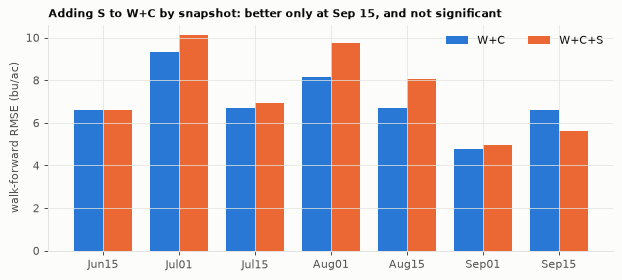

In [9]:
ps = paired[(paired["scheme"] == "wf") & (paired["base"] == "W+C") & (paired["snapshot"] != "ALL")]
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(ps)); w = 0.38
ax.bar(x - w / 2, ps["rmse_base"], w, color=C1, label="W+C")
ax.bar(x + w / 2, ps["rmse_with_s"], w, color=C2, label="W+C+S")
ax.set_xticks(x); ax.set_xticklabels(ps["snapshot"])
ax.set_ylabel("walk-forward RMSE (bu/ac)")
ax.set_title("Adding S to W+C by snapshot: better only at Sep 15, and not significant", loc="left", fontsize=9)
ax.legend(ncol=2)
fig.tight_layout()

## 2012: why satellite data arrives too late

2012 is a training season (not traded), but it shows the mechanism. The dashed lines mark the first date each signal fired.

EDD 14d > 20     Jun 27
G/E anom < -10   Jun 26
NDVI z < -1      Aug 09
price peak       Aug 21

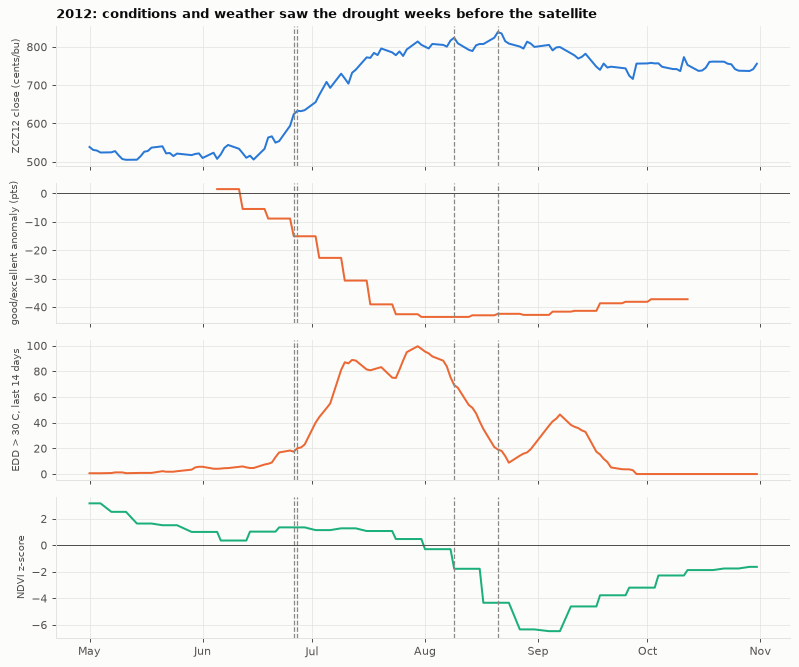

In [10]:
import matplotlib.dates as mdates
tr = pd.read_parquet(DATA_PROCESSED / "features_trading.parquet")
f = tr[(tr["campaign"] == 2012) & (tr["date"].dt.month.between(5, 10))]
panels = [("close", "ZCZ12 close (cents/bu)", C1), ("ge_anom", "good/excellent anomaly (pts)", C2),
          ("edd30_14d", "EDD > 30 C, last 14 days", C2), ("ndvi_z", "NDVI z-score", C3)]
marks = [(f.loc[f["edd30_14d"] > 20, "date"].min(), "EDD 14d > 20"),
         (f.loc[f["ge_anom"] < -10, "date"].min(), "G/E anom < -10"),
         (f.loc[f["ndvi_z"] < -1, "date"].min(), "NDVI z < -1"),
         (f.loc[f["close"].idxmax(), "date"], "price peak")]
fig, axes = plt.subplots(4, 1, figsize=(9, 7.5), sharex=True)
for ax, (c, lab, col) in zip(axes, panels):
    ax.plot(f["date"], f[c], color=col)
    ax.set_ylabel(lab, fontsize=8)
    for d, _ in marks:
        ax.axvline(d, color=NEUTRAL, lw=1, ls="--")
    if c in ("ge_anom", "ndvi_z"):
        ax.axhline(0, color=INK2, lw=0.8)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
axes[0].set_title("2012: conditions and weather saw the drought weeks before the satellite", loc="left")
fig.tight_layout()
for d, t in marks:
    print(f"{t:16s} {d:%b %d}")

- Extreme heat (14-day EDD above 20) appeared on **Jun 27** (with the 3-day weather lag), and the G/E rating was more than 10 points below normal by **Jun 26**. ZCZ12 had already started rallying in mid-June.
- US `ndvi_z` only fell below -1 on **Aug 9**, after a 14-day publication lag and with 16-day composites. The price peaked on **Aug 21**.
- By the time the satellite confirms damage, conditions, weather and the market have already priced it.

## Verdict

**Negative.** The satellite features add no measurable yield accuracy, and no model strategy beats a plain always-short Jun-Sep after costs.

- **Stage A, yield.** On the honest walk-forward (12 scored seasons, 2014-2025), no feature set beats the trend-only forecast on average over the snapshots (trend 6.4 bu/ac; best set C 6.7). The USDA forecast beats every model by a wide margin from mid-August (4.2 and 3.6 vs 6.2-8.1 at Aug 15 and 4.5-7.2 at Sep 15). Adding S to W+C makes the season-average error worse (RMSE 7.1 to 7.6; S helps in 5 of 12 seasons; p = 0.21 t-test, 0.38 Wilcoxon). The one snapshot where S looked helpful (Sep 15, 6.6 to 5.6, 8/12 seasons) is not significant after the audit fixes (p = 0.13 / 0.08), and it comes after the USDA September report, which is better still.
- **Stage B, trading.** Of 15 model strategies the best is `vs_usda|C` (+4,190, Sharpe 0.35, P&L CI -6,355 ... 16,048), which compares the C-model with the latest USDA forecast and uses no satellite data. It is far below always-short (+24,035). No model strategy has a P&L bootstrap CI that excludes zero on the positive side. The pre-audit headline `change|W` (+$10,882) was an artefact of the 1-day weather lag and of model churn: it is +1,105 now.
- **Satellite vs no satellite (trading).** W+C+S is far below always-short and not distinguishable from flat under any rule (level -2,578, change +1,892, vs_usda -400). S alone is indistinguishable from flat or random.
- **Always-short** (+24,035, Sharpe 0.93, 10/13 seasons positive) is the only result that clears the season bootstrap (P(P&L <= 0) = 0.002) at a Bonferroni-style level; its random-sign p-values (0.015 full, 0.012 own) clear 5% but not 0.05/18. It is the known seasonal weather-premium decay, not something this project discovered, and 13 seasons is a short sample.

## Caveats

- **Exploratory, not pre-registered.** The design note was committed together with the results; thresholds, feature sets and rules were chosen by people who then saw the data. The S feature mix (`ndvi_z`, `evi_anom_cum`, `ndvi_trend_anom`) was not specified in advance.
- **Multiple comparisons.** About 18 strategies and 21 snapshot x pair tests: read any single significant result with a Bonferroni-style correction (0.05/18 = 0.003). Only the always-short bootstrap passes.
- **Small sample.** 12 scored walk-forward seasons (2014-2025) and 13 trading seasons (2014-2026); 2012 (-38 bu/ac) dominates the early fits. Power to detect anything short of a large effect is low (the data cannot rule out a gain of about 1 bu/ac RMSE, but show no sign of one).
- **Reprocessed MODIS (C6.1) and reanalysis weather.** Today's archive is not what was available in real time; the 14-day lag is an approximation. NASA POWER is gridded reanalysis at 35 points with an assumed 3-day availability lag.
- **2025 satellite gap.** MODIS is NaN after Aug 10, 2025, so S strategies are flat for the rest of 2025. **2026 is partial** (no final yield; traded, not scored).
- **Trading assumptions.** One contract at the settlement close; no margin or interest on collateral; liquidity and limit-move days ignored. Stored FINAL yields are later NASS revisions (difference at most about 0.7 bu/ac).